# Public data experiments
This is the notebook to run the public data experiment

In [1]:
import sys
from pathlib import Path

# Add the workspace root to sys.path
workspace_root = Path("/Users/eduardohome/workspace/benchmark_credit_scoring")
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

# Now you can import from src
from src.utils.csv_config import read_csv_by_name, create_imbalanced_datasets, merge_xai_results
from src.model.functions import save_model, load_model, get_split_data
from src.xai.functions import get_train_iterations_shap, compute_xai_metrics_from_shap
from src.graph.functions import plot_model_boxplot, plot_imbalance_boxplot_grid

try:
    from src.model.functions import get_train_model
except Exception as exc:
    # provide helpful message if import fails
    print("Failed to import model utilities:", exc)
    print("This often means a missing dependency such as libomp for LightGBM.")
    print("On macOS you can install it with `brew install libomp` and then restart the kernel.")
    raise

# General imports
import pandas as pd
from pathlib import Path

In [2]:
# -------------------------
# Settings
# -------------------------
data_dir = Path("/Users/eduardohome/workspace/benchmark_credit_scoring/data")
#datasets_to_run = ["australian", "german", "japan", "kgccdea", "taiwan", "th02"] #kggmsc #taiwan
datasets_to_run = ["australian", "german", "japan", "kgccdea", "th02"] #kggmsc #taiwan
#datasets_to_run = ["australian"]
target_col = "target"

# Edit this list whenever you want more/less imbalance datasets
imbalance_levels = [10, 15, 20, 25, 30, 35, 40, 45, 50]
#imbalance_levels = [1, 2.5, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
n_iterations = 100
percentage = 90

# list of estimators understood by functions.get_model
model_choices = ["RandomForest", "XGBoost", "LightGBM", "BoostDT", "BoostSGB", "BagNN", "AdaBoost-DT", "ANN"] #, "SVM-Rbf"
#model_choices = ["XGBoost"] #, "SVM-Rbf"
product = "default"

## Create the imbalance datasets

In [3]:
for dataset_name in datasets_to_run:
    dataset_path = data_dir / "input" / f"{dataset_name}.csv"
    # Check if file exists and read it using the helper from src.csv_config
    if dataset_path.exists():
        # Use the dataset-specific defaults (german uses tab separator)
        create_imbalanced_datasets(
            dataset_name=dataset_name,
            data_dir=data_dir,
            imbalance_levels=imbalance_levels,  # <-- modify freely
            target_col="target",
            )

Original dataset: australian
Total samples: 690
Positive samples: 307
Negative samples: 383
Positive rate: 0.4449

australian_10.csv | Total=425 | Pos=42 | Rate=0.0988 | keep all negatives (383), downsample positives to 42
australian_15.csv | Total=450 | Pos=67 | Rate=0.1489 | keep all negatives (383), downsample positives to 67
australian_20.csv | Total=478 | Pos=95 | Rate=0.1987 | keep all negatives (383), downsample positives to 95
australian_25.csv | Total=510 | Pos=127 | Rate=0.2490 | keep all negatives (383), downsample positives to 127
australian_30.csv | Total=547 | Pos=164 | Rate=0.2998 | keep all negatives (383), downsample positives to 164
australian_35.csv | Total=589 | Pos=206 | Rate=0.3497 | keep all negatives (383), downsample positives to 206
australian_40.csv | Total=638 | Pos=255 | Rate=0.3997 | keep all negatives (383), downsample positives to 255
australian_45.csv | Total=682 | Pos=307 | Rate=0.4501 | keep all positives (307), downsample negatives to 375
australian_

## Train the models

In [4]:
results = []

for dataset_name in datasets_to_run:
    # variants for this dataset
    dataset_variants = [dataset_name] + [f"{dataset_name}_{pct}" for pct in imbalance_levels]

    # ensure output dir exists
    out_dir = data_dir / "output" / dataset_name
    out_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "#" * 90)
    print(f"BASE DATASET: {dataset_name}")
    print("#" * 90)

    for dataset_variant in dataset_variants:
        dataset_path = data_dir / "intermediate" / dataset_name / f"{dataset_variant}.csv"

        if not dataset_path.exists():
            print(f"[SKIP] File not found: {dataset_path}")
            continue

        # Read each dataset variant (uses your resolver logic in csv_config.py)
        df = pd.read_csv(str(dataset_path))

        # Basic safety checks
        if target_col not in df.columns:
            print(f"[SKIP] {dataset_variant}: target column '{target_col}' not found. Columns={list(df.columns)[:10]}...")
            continue

        # Quick dataset stats
        n_total = len(df)
        # Make sure sum/mean work even if target is int-like
        y = pd.to_numeric(df[target_col], errors="coerce")
        n_pos = int((y == 1).sum())
        pos_rate = float((y == 1).mean())

        print("\n" + "=" * 80)
        print(f"DATASET: {dataset_variant} | n={n_total} | pos={n_pos} | pos_rate={pos_rate:.4f}")
        print("=" * 80)

        # Prepare column lists for this df
        feature_cols     = df.columns.tolist()
        numerical_cols   = df.select_dtypes(include="number").columns.tolist()
        categorical_cols = df.select_dtypes(include="object").columns.tolist()
        ids_cols         = []
        target_cols      = [target_col]
        exclude_cols     = []

        # Optionally skip if only one class present (prevents stratify crash)
        n_neg = n_total - n_pos
        if n_pos == 0 or n_neg == 0:
            print(f"[SKIP] {dataset_variant}: only one class present (pos={n_pos}, neg={n_neg}).")
            continue

        for model_choice in model_choices:
            print(f"\n=== training {model_choice} on {dataset_variant} ===")

            pipeline, best_params, best_score = get_train_model(
                data=df,
                feature_cols=feature_cols,
                numerical_cols=numerical_cols,
                categorical_cols=categorical_cols,
                ids_cols=ids_cols,
                target_cols=target_cols,
                exclude_cols=exclude_cols,
                product=product,
                algorithm=model_choice,
                test_mode=True,  # set False for full search
            )

            print("Best hyperparameters:", best_params)
            print("Best CV score:", best_score)

            model_path = out_dir / "model" /f"{dataset_variant}_{model_choice}.pkl"
            save_model(str(model_path), pipeline, environment="local")
            print(f"trained pipeline saved to {model_path}")

            results.append(
                {
                    "base_dataset": dataset_name,
                    "dataset_variant": dataset_variant,
                    "model": model_choice,
                    "n_total": n_total,
                    "n_pos": n_pos,
                    "pos_rate": pos_rate,
                    "params": best_params,
                    "score": best_score,
                }
            )

results_df = pd.DataFrame(results)
results_df


##########################################################################################
BASE DATASET: australian
##########################################################################################
[SKIP] File not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/intermediate/australian/australian.csv

DATASET: australian_10 | n=425 | pos=42 | pos_rate=0.0988

=== training RandomForest on australian_10 ===
Search space for algorithm=RandomForest, product=default, test_mode=True: {'model__n_estimators': Integer(low=50, high=300, prior='uniform', transform='identity'), 'model__max_depth': Integer(low=1, high=50, prior='uniform', transform='identity'), 'model__min_samples_split': Integer(low=2, high=20, prior='uniform', transform='identity'), 'model__min_samples_leaf': Integer(low=1, high=10, prior='uniform', transform='identity'), 'model__max_features': Categorical(categories=('sqrt',), prior=None), 'model__bootstrap': Categorical(categories=(True, False), prior

,base_dataset,dataset_variant,model,n_total,n_pos,pos_rate,params,score
0,australian,australian_10,RandomForest,425,42,0.098824,"{'model__bootstrap': False, 'model__class_weig...",0.753858
1,australian,australian_10,XGBoost,425,42,0.098824,"{'model__booster': 'gbtree', 'model__colsample...",0.097633
2,australian,australian_10,LightGBM,425,42,0.098824,{'model__bagging_fraction': 0.9293468848796316...,0.097633
3,australian,australian_10,BoostDT,425,42,0.098824,"{'model__learning_rate': 0.07222603429369405, ...",0.694188
4,australian,australian_10,BoostSGB,425,42,0.098824,"{'model__learning_rate': 0.07222603429369405, ...",0.723732
...,...,...,...,...,...,...,...,...
355,th02,th02_50,BoostDT,646,323,0.500000,"{'model__learning_rate': 0.07222603429369405, ...",0.659118
356,th02,th02_50,BoostSGB,646,323,0.500000,"{'model__learning_rate': 0.07222603429369405, ...",0.665573
357,th02,th02_50,BagNN,646,323,0.500000,"{'model__estimator__activation': 'relu', 'mode...",0.627134
358,th02,th02_50,AdaBoost-DT,646,323,0.500000,"{'model__estimator__max_depth': 3, 'model__est...",0.569114


## SHAP iterations

In [5]:
# -------------------------
# Loop XAI iterations
# -------------------------
for dataset_name in datasets_to_run:

    dataset_variants = [dataset_name] + [f"{dataset_name}_{lvl}" for lvl in imbalance_levels]

    out_dir = data_dir / "output" / dataset_name
    out_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "#" * 90)
    print(f"BASE DATASET: {dataset_name}")
    print("#" * 90)

    for dataset_variant in dataset_variants:

        dataset_path = data_dir / "intermediate" / dataset_name / f"{dataset_variant}.csv"

        if not dataset_path.exists():
            print(f"[SKIP] File not found: {dataset_path}")
            continue

        # Same reader used during training
        path = str(dataset_path)
        df = pd.read_csv(str(path))

        if target_col not in df.columns:
            print(f"[SKIP] {dataset_variant}: target column '{target_col}' not found.")
            continue

        n_total = len(df)
        y = pd.to_numeric(df[target_col], errors="coerce")
        n_pos = int((y == 1).sum())
        pos_rate = float((y == 1).mean())

        print("\n" + "=" * 80)
        print(f"DATASET: {dataset_variant} | n={n_total} | pos={n_pos} | pos_rate={pos_rate:.4f}")
        print("=" * 80)

        n_neg = n_total - n_pos
        if n_pos == 0 or n_neg == 0:
            print(f"[SKIP] {dataset_variant}: only one class present.")
            continue

        # Same column preparation as training
        feature_cols     = df.columns.tolist()
        numerical_cols   = df.select_dtypes(include="number").columns.tolist()
        categorical_cols = df.select_dtypes(include="object").columns.tolist()
        ids_cols         = []
        target_cols      = [target_col]
        exclude_cols     = []

        # Data split
        x_train, x_test, y_train, y_test, numerical, categorical = get_split_data(
            data=df,
            feature_cols=feature_cols,
            numerical_cols=numerical_cols,
            categorical_cols=categorical_cols,
            ids_cols=ids_cols,
            target_cols=target_cols,
            exclude_cols=exclude_cols,
            test_size=0.5,
            random_state=123,
        )

        for model_choice in model_choices:

            model_path = out_dir / "model" /f"{dataset_variant}_{model_choice}.pkl"

            if not model_path.exists():
                print(f"[SKIP] Model not found: {model_path}")
                continue

            print(f"Running XAI iterations for {dataset_variant} | {model_choice}")

            pipeline = load_model(str(model_path))

            df_shap = get_train_iterations_shap(
                pipeline=pipeline,
                x_train=x_train,
                x_test=x_test,
                y_train=y_train,
                n_iterations=n_iterations,
                percentage=percentage,
            )
            # ----------------------------
            # Create output folder
            # ----------------------------
            result_dir = out_dir / "xai" / f"{model_choice}" / f"{dataset_variant}" / "shap_values"
            result_dir.mkdir(parents=True, exist_ok=True)

            # ----------------------------
            # Save outputs
            # ----------------------------
            df_shap.to_csv(
                result_dir / f"{dataset_variant}_{model_choice}_shap_values.csv",
                index=False
            )

            print(f"[OK] Saved results to {result_dir}")


##########################################################################################
BASE DATASET: australian
##########################################################################################
[SKIP] File not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/intermediate/australian/australian.csv

DATASET: australian_10 | n=425 | pos=42 | pos_rate=0.0988
Running XAI iterations for australian_10 | RandomForest
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/model/australian_10_RandomForest.pkl
[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/RandomForest/australian_10/shap_values
Running XAI iterations for australian_10 | XGBoost
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/model/australian_10_XGBoost.pkl
[OK] Saved results to /Users/eduardohome/workspace/bench

PermutationExplainer explainer: 569it [00:11,  5.99it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.73it/s]                         
PermutationExplainer explainer: 569it [00:12,  8.11it/s]                         
PermutationExplainer explainer: 569it [00:12,  8.58it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.72it/s]                         
PermutationExplainer explainer: 569it [00:11,  7.30it/s]                         
PermutationExplainer explainer: 569it [00:12,  9.11it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.66it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.50it/s]                         
PermutationExplainer explainer: 569it [00:11,  7.74it/s]                         
PermutationExplainer explainer: 569it [00:12,  7.91it/s]                         
PermutationExplainer explainer: 569it [00:11,  7.30it/s]                         
PermutationExpla

[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/kgccdea/xai/BoostDT/kgccdea_10/shap_values
Running XAI iterations for kgccdea_10 | BoostSGB
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/kgccdea/model/kgccdea_10_BoostSGB.pkl


PermutationExplainer explainer: 569it [00:11,  6.66it/s]                         
PermutationExplainer explainer: 569it [00:11,  7.64it/s]                         
PermutationExplainer explainer: 569it [00:12,  8.99it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.28it/s]                         
PermutationExplainer explainer: 569it [00:11,  5.37it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.59it/s]                         
PermutationExplainer explainer: 569it [00:11,  7.51it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.44it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.88it/s]                         
PermutationExplainer explainer: 569it [00:11,  5.54it/s]                         
PermutationExplainer explainer: 569it [00:11,  5.76it/s]                         
PermutationExplainer explainer: 569it [00:11,  6.58it/s]                         
PermutationExpla

[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/kgccdea/xai/BoostSGB/kgccdea_10/shap_values
Running XAI iterations for kgccdea_10 | BagNN
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/kgccdea/model/kgccdea_10_BagNN.pkl


...

[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/xai/BoostSGB/th02_30/shap_values
Running XAI iterations for th02_30 | BagNN
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/model/th02_30_BagNN.pkl


PermutationExplainer explainer: 539it [00:11,  6.99it/s]                         
PermutationExplainer explainer: 539it [00:11,  6.31it/s]                         
PermutationExplainer explainer: 539it [00:11,  5.93it/s]                         
PermutationExplainer explainer: 539it [00:11,  6.07it/s]                         
PermutationExplainer explainer: 539it [00:11,  6.61it/s]                         
PermutationExplainer explainer: 539it [00:11,  6.97it/s]                         
PermutationExplainer explainer: 539it [00:11,  5.87it/s]                         
PermutationExplainer explainer: 539it [00:11,  5.94it/s]                         
PermutationExplainer explainer: 539it [00:11,  6.61it/s]                         
PermutationExplainer explainer: 539it [00:11,  6.40it/s]                         
PermutationExplainer explainer: 539it [00:11,  5.93it/s]                         
PermutationExplainer explainer: 539it [00:11,  6.01it/s]                         
PermutationExpla

[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/xai/BagNN/th02_30/shap_values
Running XAI iterations for th02_30 | AdaBoost-DT
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/model/th02_30_AdaBoost-DT.pkl
[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/xai/AdaBoost-DT/th02_30/shap_values
Running XAI iterations for th02_30 | ANN
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/model/th02_30_ANN.pkl
[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/xai/ANN/th02_30/shap_values

DATASET: th02_35 | n=922 | pos=323 | pos_rate=0.3503
Running XAI iterations for th02_35 | RandomForest
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/model/th02_35_RandomForest.pkl
[OK] Saved 

PermutationExplainer explainer: 462it [00:10,  1.17it/s]                         
PermutationExplainer explainer: 462it [00:10,  1.08it/s]                         
PermutationExplainer explainer: 462it [00:10,  1.45s/it]                         
PermutationExplainer explainer: 462it [00:10,  1.17it/s]                         
PermutationExplainer explainer: 462it [00:10,  1.45it/s]                         
PermutationExplainer explainer: 462it [00:10,  2.81it/s]                         
PermutationExplainer explainer: 462it [00:10,  1.36it/s]                         
PermutationExplainer explainer: 462it [00:10,  1.13s/it]                         
PermutationExplainer explainer: 462it [00:10,  1.73it/s]                         
PermutationExplainer explainer: 462it [00:10,  2.52s/it]                 
PermutationExplainer explainer: 462it [00:10,  2.52s/it]                 
PermutationExplainer explainer: 462it [00:10,  1.64it/s]                         
PermutationExplainer explainer: 

[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/xai/BagNN/th02_35/shap_values
Running XAI iterations for th02_35 | AdaBoost-DT
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/model/th02_35_AdaBoost-DT.pkl
[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/xai/AdaBoost-DT/th02_35/shap_values
Running XAI iterations for th02_35 | ANN
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/model/th02_35_ANN.pkl
[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/xai/ANN/th02_35/shap_values

DATASET: th02_40 | n=807 | pos=323 | pos_rate=0.4002
Running XAI iterations for th02_40 | RandomForest
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/th02/model/th02_40_RandomForest.pkl
[OK] Saved 

## Interpretability metrics

In [18]:
# -------------------------
# Loop XAI metrics from saved SHAP
# -------------------------
for dataset_name in datasets_to_run:

    dataset_variants = [dataset_name] + [f"{dataset_name}_{lvl}" for lvl in imbalance_levels]

    out_dir = data_dir / "output" / dataset_name
    out_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "#" * 90)
    print(f"BASE DATASET: {dataset_name}")
    print("#" * 90)

    for dataset_variant in dataset_variants:

        for model_choice in model_choices:

            print(f"Computing XAI metrics for {dataset_variant} | {model_choice}")

            # --------------------------------------------------
            # Load previously saved SHAP file
            # --------------------------------------------------
            shap_dir = out_dir / "xai" / f"{model_choice}" / f"{dataset_variant}" / "shap_values"
            shap_path = shap_dir / f"{dataset_variant}_{model_choice}_shap_values.csv"

            if not shap_path.exists():
                print(f"[SKIP] SHAP file not found: {shap_path}")
                continue

            df_shap = pd.read_csv(shap_path)

            # Optional sanity check
            required_cols = {"n_iteration", "index"}
            missing_cols = required_cols - set(df_shap.columns)
            if missing_cols:
                print(f"[SKIP] Missing required columns in SHAP file: {missing_cols}")
                continue

            # --------------------------------------------------
            # Compute metrics from saved SHAP
            # --------------------------------------------------
            (
                df_ranking_local,
                extra_local,
                df_ranking_global,
                df_resume_local,
                df_resume_global,
                df_resume,
            ) = compute_xai_metrics_from_shap(df_shap)

            # --------------------------------------------------
            # Create output folders
            # --------------------------------------------------
            metrics_dir = out_dir / "xai" / f"{model_choice}" / f"{dataset_variant}" / "metrics"
            metrics_dir.mkdir(parents=True, exist_ok=True)

            # --------------------------------------------------
            # Save outputs
            # --------------------------------------------------
            df_ranking_local.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_ranking_local.csv",
                index=False
            )

            extra_local.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_ranking_extra_local.csv",
                index=False
            )

            df_ranking_global.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_ranking_global.csv",
                index=False
            )

            df_resume_local.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_resume_local.csv",
                index=False
            )

            df_resume_global.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_resume_global.csv",
                index=False
            )

            df_resume.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_summary.csv",
                index=False
            )

            print(f"[OK] Saved metrics to {metrics_dir}")


##########################################################################################
BASE DATASET: australian
##########################################################################################
Computing XAI metrics for australian | RandomForest
[SKIP] SHAP file not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/RandomForest/australian/shap_values/australian_RandomForest_shap_values.csv
Computing XAI metrics for australian | XGBoost
[SKIP] SHAP file not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/XGBoost/australian/shap_values/australian_XGBoost_shap_values.csv
Computing XAI metrics for australian | LightGBM
[SKIP] SHAP file not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/LightGBM/australian/shap_values/australian_LightGBM_shap_values.csv
Computing XAI metrics for australian | BoostDT
[SKIP] SHAP file not found: /Users/eduardohome/workspace/benc

## Summary results

In [7]:
results = merge_xai_results(
    data_dir=data_dir,
    datasets_to_run=datasets_to_run,
    imbalance_levels=imbalance_levels,
    model_choices=model_choices,
    file_types=["resume_local", "resume_global", "summary"],
    normalize=True,
)



Processing dataset: australian
  Merging file type: resume_local
Saved raw merged dataset: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/australian_xai_all_models_resume_local.csv
Saved normalized merged dataset: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/australian_xai_all_models_resume_local_normalized.csv
  Merging file type: resume_global
Saved raw merged dataset: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/australian_xai_all_models_resume_global.csv
Saved normalized merged dataset: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/australian_xai_all_models_resume_global_normalized.csv
  Merging file type: summary
Saved raw merged dataset: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/australian/xai/australian_xai_all_models_summary.csv
Saved normalized merged dataset: /Users/eduardohome/workspace/benchmark_credit_scoring/

## Read data 

In [32]:
import pandas as pd
from pathlib import Path


def load_xai_file(
    data_dir,
    dataset_name,
    dataset_variant=None,
    model_choice=None,
    file_type="summary",
    normalized=False,
):
    """
    Load saved XAI result files.

    Supports:
    --------
    1) Standard model-level files
       Example:
       german_5_XGBoost_summary.csv
       german_5_XGBoost_resume_local.csv
       german_5_XGBoost_resume_global.csv

    2) Merged all-models files created by merge_xai_results()
       Example:
       german_xai_all_models_summary.csv
       german_xai_all_models_summary_normalized.csv
       german_xai_all_models_resume_local.csv
       german_xai_all_models_resume_global.csv

    Parameters
    ----------
    data_dir : str | Path
        Base project directory.

    dataset_name : str
        Dataset name, e.g. "german"

    dataset_variant : str | None
        Variant name, e.g. "german_5"
        Required only for model-level files.

    model_choice : str | None
        Model name, e.g. "XGBoost"
        Required only for model-level files.

    file_type : str
        Accepted values:

        Model-level files:
            "summary"
            "resume_local"
            "resume_global"

        Merged files:
            "all_models_summary"
            "all_models_resume_local"
            "all_models_resume_global"

    normalized : bool, default=False
        Used only for merged files.

    Returns
    -------
    pd.DataFrame
    """

    data_dir = Path(data_dir)

    # ===================================================
    # MERGED FILES
    # ===================================================
    merged_prefix = "all_models_"

    if file_type.startswith(merged_prefix):

        base_type = file_type.replace(merged_prefix, "")
        suffix = "_normalized" if normalized else ""

        file_path = (
            data_dir
            / "output"
            / dataset_name
            / "xai"
            / f"{dataset_name}_xai_all_models_{base_type}{suffix}.csv"
        )

        if not file_path.exists():
            raise FileNotFoundError(f"File not found: {file_path}")

        return pd.read_csv(file_path)

    # ===================================================
    # STANDARD MODEL FILES
    # ===================================================
    if dataset_variant is None or model_choice is None:
        raise ValueError(
            "dataset_variant and model_choice are required "
            "for model-level files."
        )

    result_dir = (
        data_dir
        / "output"
        / dataset_name
        / "xai"
        / model_choice
        / dataset_variant
        / "metrics"
    )

    file_path = result_dir / f"{dataset_variant}_{model_choice}_{file_type}.csv"

    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}")

    return pd.read_csv(file_path)

In [33]:
dataset = "australian"

In [55]:
df_all_summary = load_xai_file(
    data_dir=data_dir,
    dataset_name=dataset,
    file_type="all_models_resume_global",
)
df_all_summary.head()

,feature,rankstab_global,feature_importance,value_stab,rankstab_global_weight,value_stab_weight,dataset,imbalance,model
0,0.0,2.391866,0.000683,0.731213,0.001633,0.000499,australian,10,RandomForest
1,1.0,0.458649,0.028842,0.173050,0.013229,0.004991,australian,10,RandomForest
2,2.0,0.263250,0.006171,0.186665,0.001625,0.001152,australian,10,RandomForest
3,3.0,2.331295,0.002323,0.325730,0.005415,0.000757,australian,10,RandomForest
4,4.0,0.496700,0.009497,0.209669,0.004717,0.001991,australian,10,RandomForest


In [56]:
df_all_summary[(df_all_summary.model == "RandomForest") & (df_all_summary.imbalance == 15)]

,feature,rankstab_global,feature_importance,value_stab,rankstab_global_weight,value_stab_weight,dataset,imbalance,model
96,0.0,1.849738,0.000845,0.402109,0.001563,0.000340,australian,15,RandomForest
97,1.0,0.777422,0.006695,0.234604,0.005205,0.001571,australian,15,RandomForest
98,2.0,0.286255,0.010361,0.204963,0.002966,0.002124,australian,15,RandomForest
99,3.0,0.721510,0.005436,0.230674,0.003922,0.001254,australian,15,RandomForest
100,4.0,0.688022,0.016852,0.170434,0.011595,0.002872,australian,15,RandomForest
101,5.0,0.587847,0.003464,0.230538,0.002036,0.000799,australian,15,RandomForest
102,6.0,1.863036,0.023074,0.166410,0.042987,0.003840,australian,15,RandomForest
103,7.0,1.186275,0.086734,0.049545,0.102891,0.004297,australian,15,RandomForest
104,8.0,1.273151,0.023336,0.108158,0.029710,0.002524,australian,15,RandomForest
105,9.0,0.794118,0.039593,0.090587,0.031441,0.003587,australian,15,RandomForest


In [44]:
14 * 9 * 8

1008

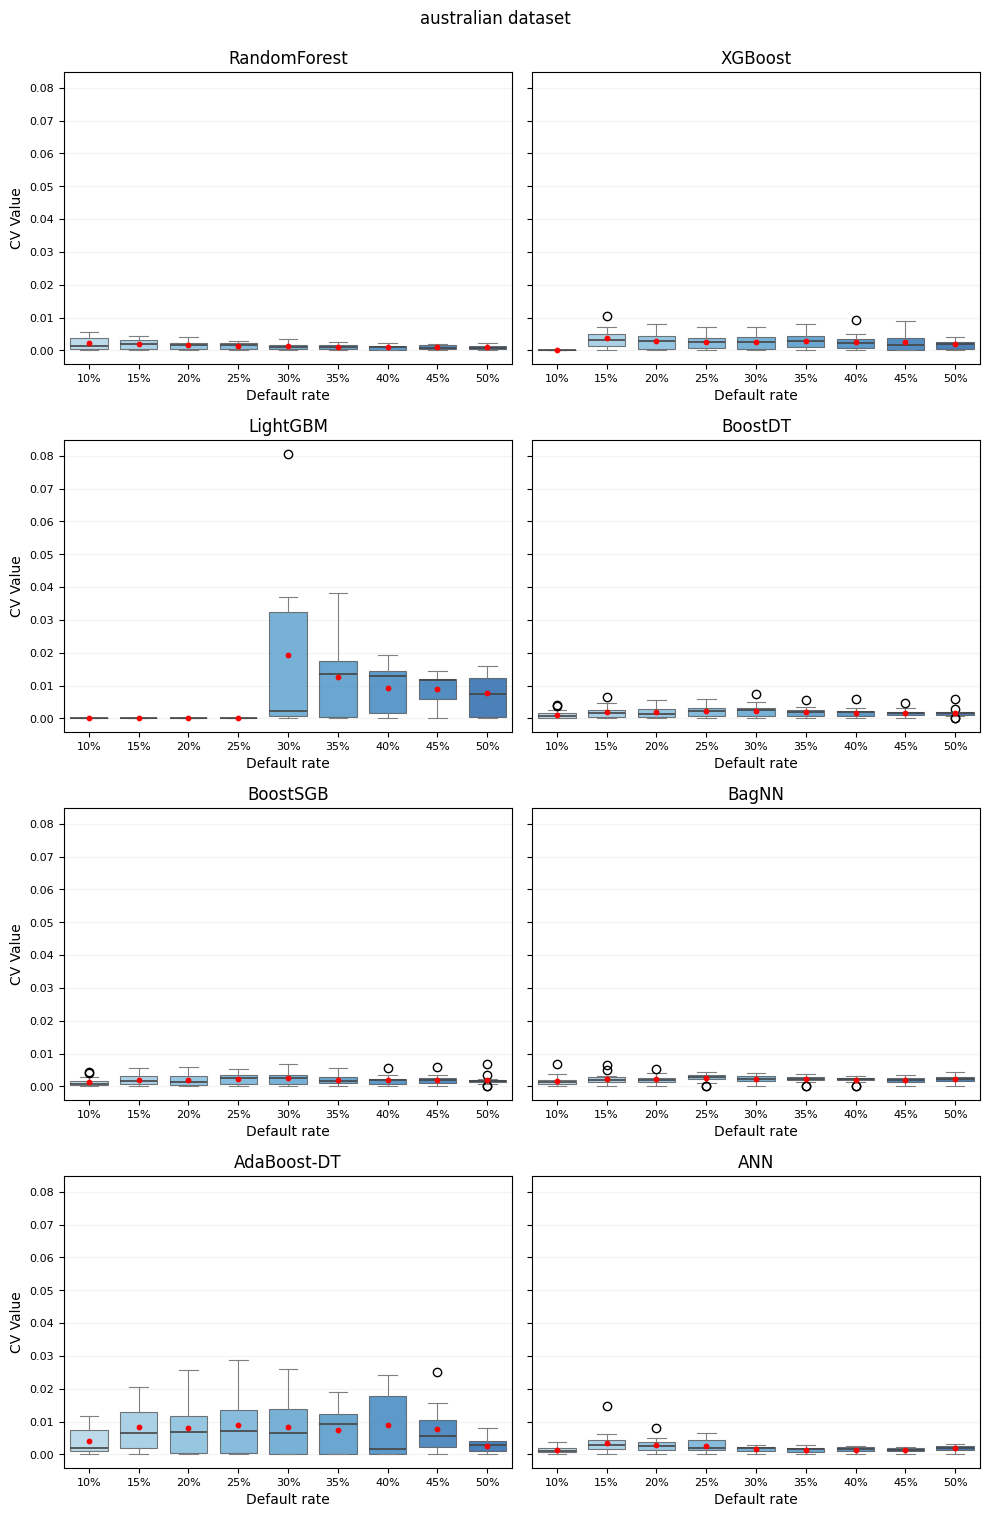

In [30]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_all_summary,
    dataset=dataset,
    models=model_choices,
    metric="value_stab_weight",
    ylabel="CV Value",
    xlabel="Default rate",
    imbalance_order=imbalance_levels,
    ncols=2,
    suptitle=f"{dataset} dataset"
)

plt.show()


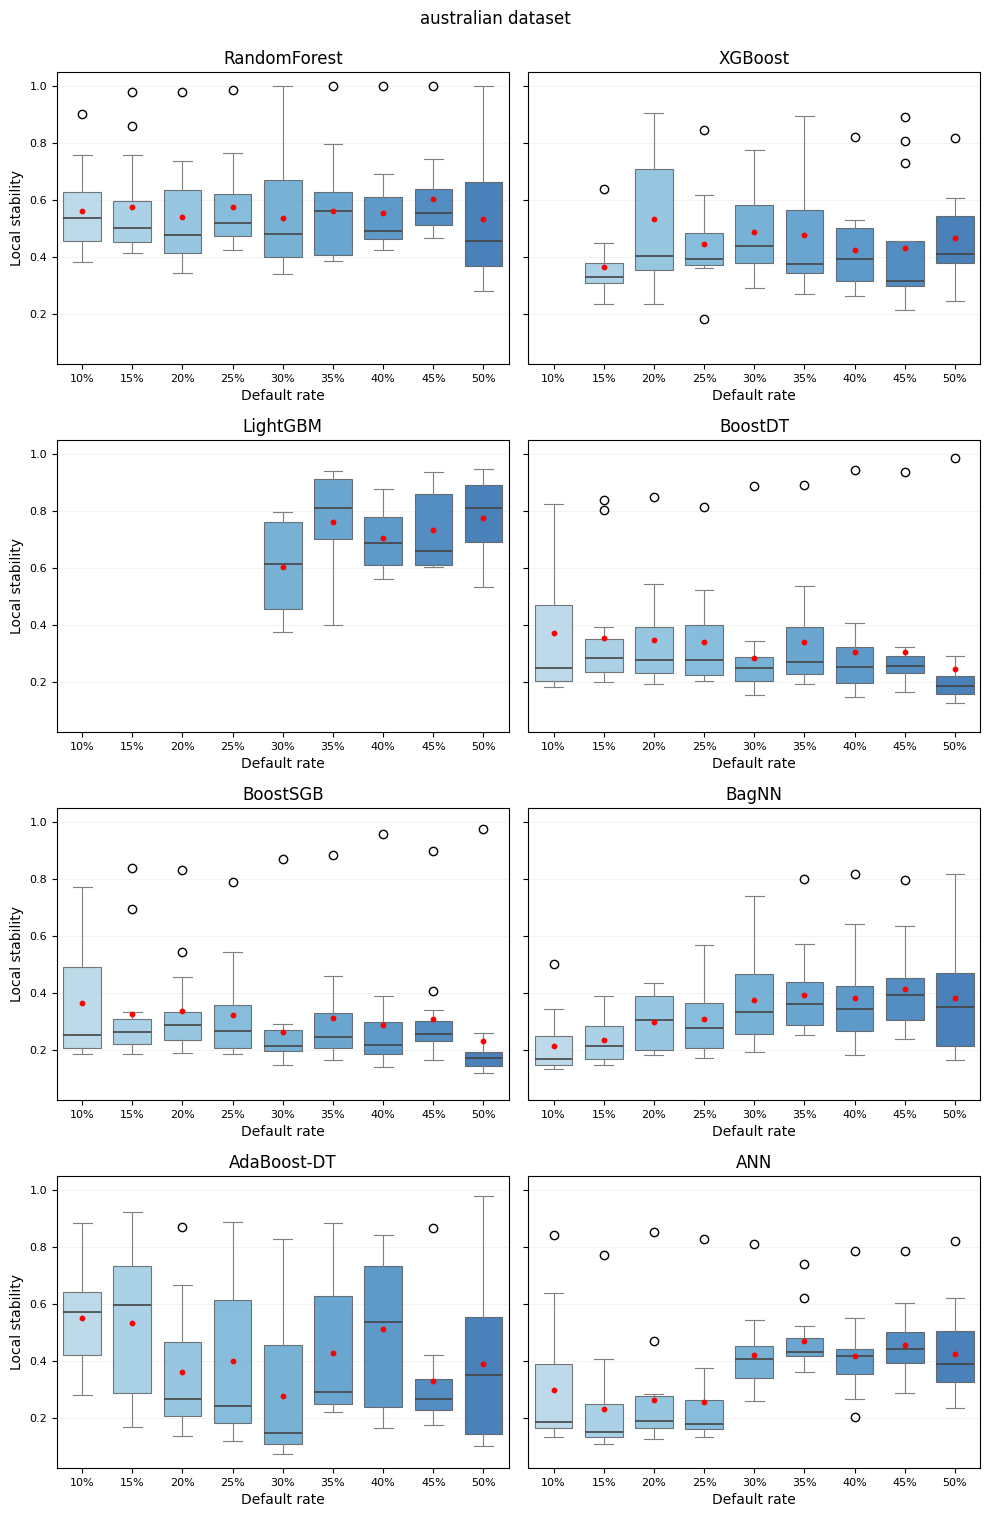

In [28]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_all_summary,
    dataset=dataset,
    models=model_choices,
    metric="rankstab_local",
    ylabel="Local stability",
    xlabel="Default rate",
    imbalance_order=imbalance_levels,
    ncols=2,
    suptitle=f"{dataset} dataset"
)

plt.show()


In [25]:
df_all_global = load_xai_file(
    data_dir=data_dir,
    dataset_name=dataset,
    file_type="all_models_resume_global",
)  
df_all_global.head()

,feature,rankstab_global,feature_importance,value_stab,rankstab_global_weight,value_stab_weight,dataset,imbalance,model
0,0.0,2.391866,0.000683,0.731213,0.001633,0.000499,australian,10,RandomForest
1,1.0,0.458649,0.028842,0.173050,0.013229,0.004991,australian,10,RandomForest
2,2.0,0.263250,0.006171,0.186665,0.001625,0.001152,australian,10,RandomForest
3,3.0,2.331295,0.002323,0.325730,0.005415,0.000757,australian,10,RandomForest
4,4.0,0.496700,0.009497,0.209669,0.004717,0.001991,australian,10,RandomForest


In [26]:
df_all_global.value_stab_weight.describe()

count    990.000000
mean       0.002973
std        0.004911
min        0.000000
25%        0.000677
50%        0.001824
75%        0.003119
max        0.080646
Name: value_stab_weight, dtype: float64

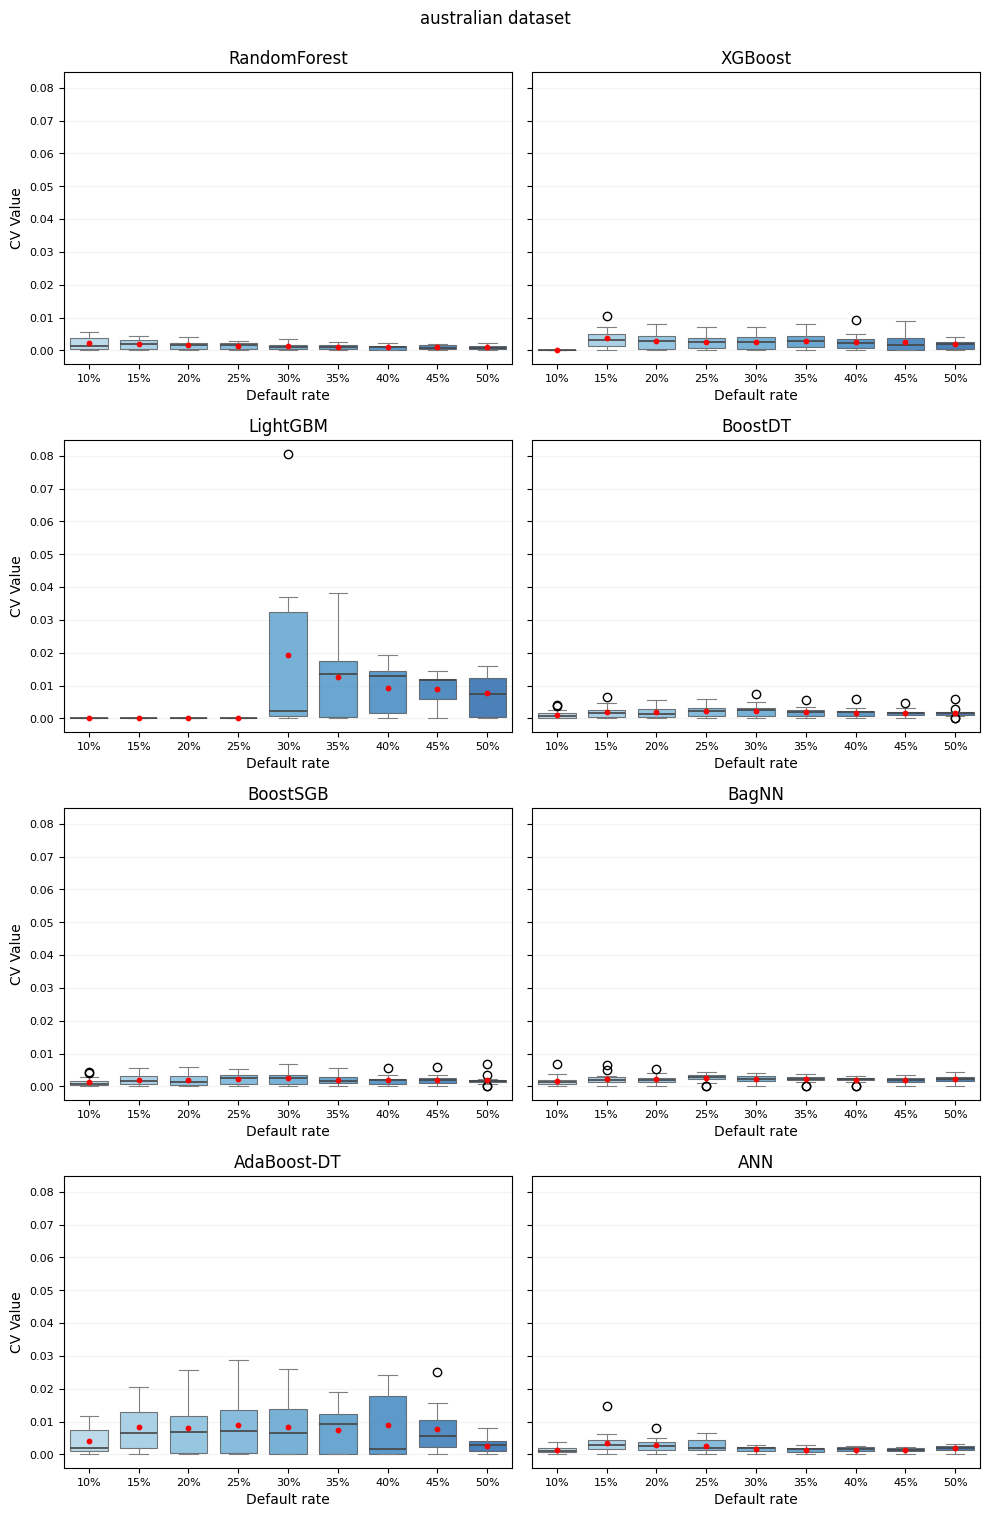

In [15]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_all_global,
    dataset=dataset,
    models=model_choices,
    metric="value_stab_weight",
    ylabel="CV Value",
    xlabel="Default rate",
    imbalance_order=imbalance_levels,
    ncols=2,
    suptitle=f"{dataset} dataset"
)

plt.show()


In [16]:
df_all_global = load_xai_file(
    data_dir=data_dir,
    dataset_name=dataset,
    file_type="all_models_resume_global",
)  
df_all_global.head()

,feature,rankstab_global,feature_importance,value_stab,rankstab_global_weight,value_stab_weight,dataset,imbalance,model
0,0.0,2.391866,0.000683,0.731213,0.001633,0.000499,australian,10,RandomForest
1,1.0,0.458649,0.028842,0.173050,0.013229,0.004991,australian,10,RandomForest
2,2.0,0.263250,0.006171,0.186665,0.001625,0.001152,australian,10,RandomForest
3,3.0,2.331295,0.002323,0.325730,0.005415,0.000757,australian,10,RandomForest
4,4.0,0.496700,0.009497,0.209669,0.004717,0.001991,australian,10,RandomForest


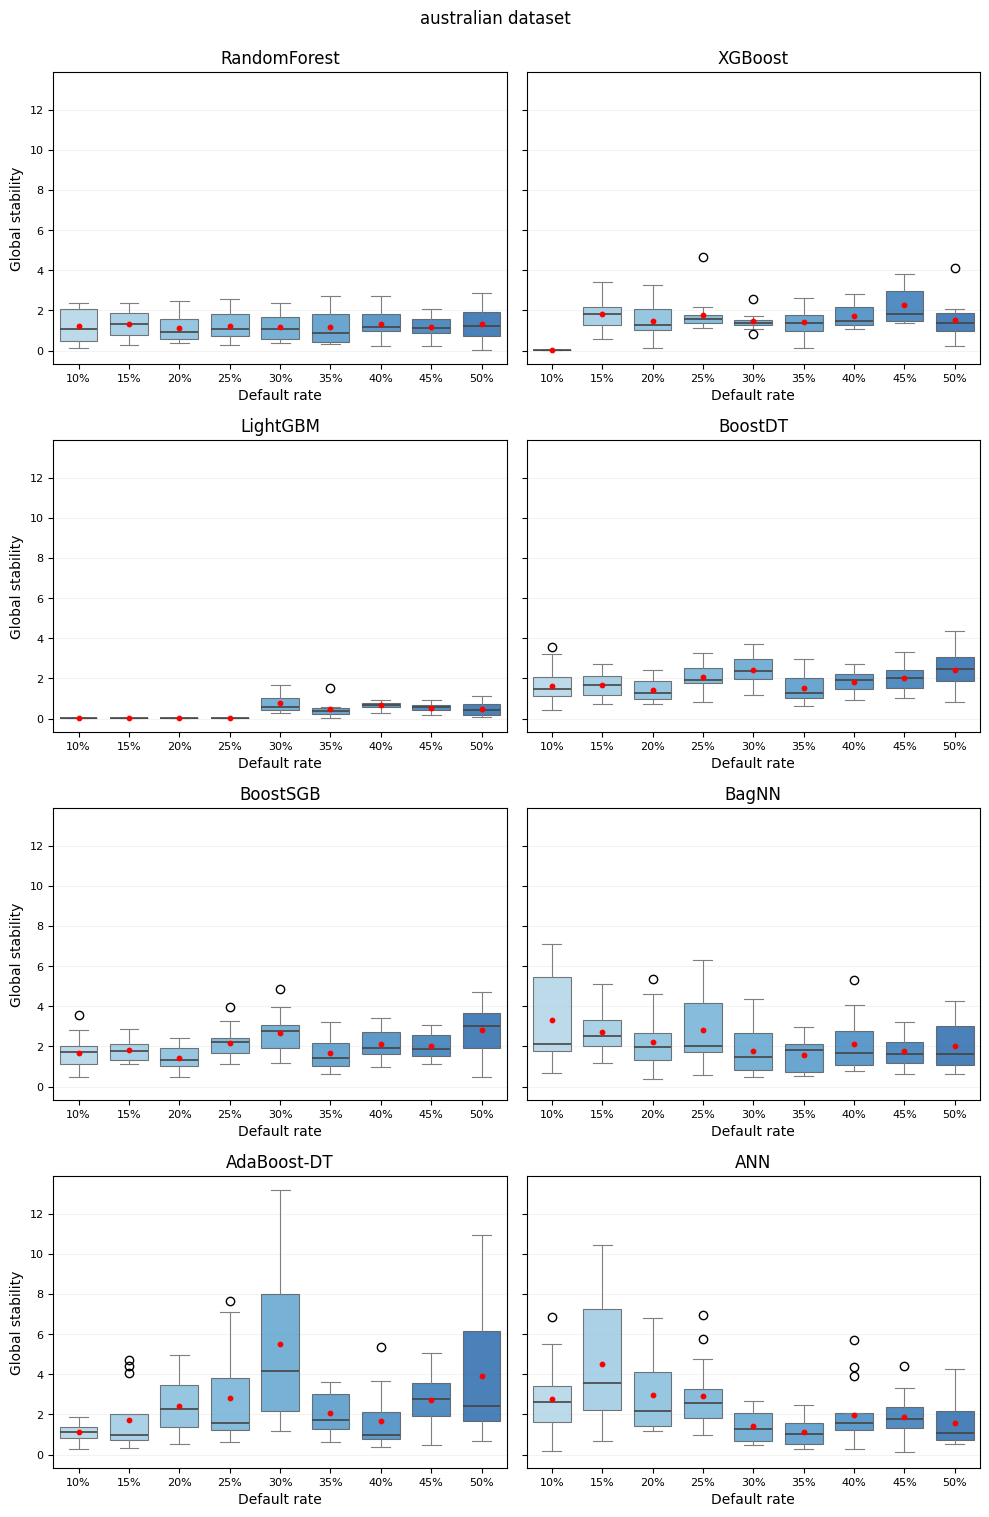

In [27]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_all_global,
    dataset=dataset,
    models=model_choices,
    metric="rankstab_global",
    ylabel="Global stability",
    xlabel="Default rate",
    imbalance_order=imbalance_levels,
    ncols=2,
    suptitle=f"{dataset} dataset"
)

plt.show()
